# Plot Dispersion Curves

This notebook loads dispersion curve results from `04_XROMY_event_analysis_vel.py` and creates visualization plots.

## Notebook Overview
This notebook visualizes ROMY dispersion results and compares them with reference model curves.

**Main workflow**
- Load dispersion result tables from `output/`.
- Choose per-event velocity estimate: `kde_peak` or `median`.
- Filter/group results by wave type and method.
- Plot dispersion curves with uncertainties/statistics.
- Overlay reference model predictions from `data/`.
- Export publication-style summary figures.

## Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt


## Configuration

In [2]:
# Path to dispersion results CSV
path_to_data = "./output/results_dispersion_romy.csv"

# Per-event velocity estimate to plot: 'kde_peak' or 'median'
velocity_estimate = "kde_peak"  # 'kde_peak' | 'median'

VELOCITY_COLUMN_MAP = {
    "kde_peak": "velocity",
    "median": "velocity_median",
}
VELOCITY_UNCERTAINTY_COLUMN_MAP = {
    "kde_peak": "velocity_uncertainty",
    "median": "velocity_median_uncertainty",
}
VELOCITY_LABEL_MAP = {
    "kde_peak": "KDE peak",
    "median": "Median",
}

if velocity_estimate not in VELOCITY_COLUMN_MAP:
    raise ValueError("velocity_estimate must be 'kde_peak' or 'median'")

velocity_column = VELOCITY_COLUMN_MAP[velocity_estimate]
velocity_uncertainty_column = VELOCITY_UNCERTAINTY_COLUMN_MAP[velocity_estimate]
velocity_label = VELOCITY_LABEL_MAP[velocity_estimate]

# set cc threshold
cc_threshold = 0.85

# Output directory for figures
output_dir = "./output/figures/dispersion"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

## Load Dispersion Data

In [3]:
# Load dispersion curves CSV
df = pd.read_csv(path_to_data)

if velocity_column not in df.columns:
    if velocity_estimate == "median":
        raise ValueError(
            f"Column '{velocity_column}' not found in {path_to_data}. "
            "Re-run 04_XROMY_event_analysis_vel.py to export per-band median velocities."
        )
    raise ValueError(f"Required column '{velocity_column}' not found in {path_to_data}")

print(f"Loaded {len(df)} data points")
print(f"Velocity estimate: {velocity_label} ({velocity_column})")
print(f"\nColumns: {list(df.columns)}")
print(f"\nWave types: {df['wave_type'].unique()}")
print(f"\nCC methods: {df['cc_method'].unique()}")
print(f"\nEvents: {df['event_date'].unique()}")
df.head()

Loaded 1520 data points
Velocity estimate: KDE peak (velocity)

Columns: ['event_date', 'origin_time', 'magnitude', 'distance_km', 'wave_type', 'cc_method', 'frequency', 'velocity', 'velocity_median', 'velocity_uncertainty', 'velocity_median_uncertainty', 'cc', 'n_samples']

Wave types: ['love' 'rayleigh']

CC methods: ['mid' 'max']

Events: [20190514 20230908 20230912 20231202 20240314 20240322 20240323 20240414
 20240422 20240815 20240915 20241023 20250513 20250602 20251206 20251212
 20251227 20260107 20260420]


,event_date,origin_time,magnitude,distance_km,wave_type,cc_method,frequency,velocity,velocity_median,velocity_uncertainty,velocity_median_uncertainty,cc,n_samples
0,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,love,mid,0.01000,3300.0,3287.198260,378.0,1336.134823,0.89,13
1,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,love,mid,0.01259,2800.0,2829.031334,412.0,1551.084809,0.97,11
2,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,love,mid,0.01585,3000.0,3030.649302,583.0,582.372672,0.98,15
3,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,love,mid,0.01995,4400.0,4264.262564,755.0,894.238280,0.96,23
4,20190514,2019-05-14T12:58:25.939000Z,7.6,13894.14,love,mid,0.02512,3000.0,4007.653407,758.0,2586.377455,0.94,34


## Convert Each Event to DataFrame

Convert each event's dispersion data into DataFrames with frequencies as rows, grouped by wave type and CC method.

In [4]:
# Convert each event to a DataFrame with frequencies as rows
# Group by wave_type and cc_method
df_dict = {}

for wave_type in ['love', 'rayleigh']:
    for cc_method in ['mid', 'max']:
        key = f"{wave_type}_{cc_method}"
        df_dict[key] = {}
        
        df_subset = df[(df['wave_type'] == wave_type) & (df['cc_method'] == cc_method)].copy()
        
        if len(df_subset) == 0:
            continue
        
        # Get unique events
        events = df_subset['event_date'].unique()
        
        for event in events:
            event_data = df_subset[df_subset['event_date'] == event].copy()
            
            # Filter valid data
            frequencies = event_data['frequency'].values
            velocities = event_data[velocity_column].values
            
            # Filter to keep only valid values (finite frequencies and positive velocities)
            valid_mask = np.isfinite(velocities) & (velocities > 0) & np.isfinite(frequencies) & (frequencies > 0)
            frequencies_valid = frequencies[valid_mask]
            velocities_valid = velocities[valid_mask]
            
            if len(frequencies_valid) > 0:
                # Create DataFrame with frequencies as index
                df_temp = pd.DataFrame({
                    'velocity': velocities_valid
                }, index=frequencies_valid)
                
                # Remove duplicate frequencies (keep first occurrence)
                df_temp = df_temp.groupby(df_temp.index).first()
                
                # Sort by frequency
                df_temp = df_temp.sort_index()
                
                df_dict[key][event] = df_temp
                df_dict[key][event].index.name = 'frequency'

print(f"Converted data for {len([k for k in df_dict.keys() if len(df_dict[k]) > 0])} wave type/method combinations")
for key in df_dict.keys():
    if len(df_dict[key]) > 0:
        print(f"  {key}: {len(df_dict[key])} events")

Converted data for 4 wave type/method combinations
  love_mid: 19 events
  love_max: 19 events
  rayleigh_mid: 19 events
  rayleigh_max: 19 events


## Find Event with Most Frequencies and Merge DataFrames

For each wave type and CC method combination, find the event with the most frequencies and merge all events.

In [5]:
# Merge DataFrames for each wave type and CC method combination
merged_dfs = {}

for key in df_dict.keys():
    if len(df_dict[key]) == 0:
        continue
    
    # Find event with most frequencies
    lengths = {event: len(df.index) for event, df in df_dict[key].items()}
    longest_event = max(lengths, key=lengths.get)
    longest_frequencies = df_dict[key][longest_event].index.values
    
    # Ensure frequencies are unique and sorted
    longest_frequencies = np.unique(longest_frequencies)
    longest_frequencies = np.sort(longest_frequencies)
    
    print(f"{key}: Event with most frequencies: {longest_event} ({len(longest_frequencies)} frequencies)")
    if len(longest_frequencies) > 0:
        print(f"  Frequency range: {longest_frequencies[0]:.4f} - {longest_frequencies[-1]:.4f} Hz")
    
    # Merge all DataFrames based on longest frequencies
    df_merged = pd.DataFrame(index=longest_frequencies)
    df_merged.index.name = 'frequency'
    
    for event_name, df_event in df_dict[key].items():
        # Reindex to match longest frequency array (fills missing with NaN)
        series = df_event['velocity']
        df_merged[event_name] = series.reindex(longest_frequencies)
    
    merged_dfs[key] = df_merged
    print(f"  Merged DataFrame: {len(df_merged)} frequency points, {len(df_merged.columns)} events\n")

love_mid: Event with most frequencies: 20190514 (20 frequencies)
  Frequency range: 0.0100 - 0.7943 Hz
  Merged DataFrame: 20 frequency points, 19 events

love_max: Event with most frequencies: 20190514 (20 frequencies)
  Frequency range: 0.0100 - 0.7943 Hz
  Merged DataFrame: 20 frequency points, 19 events

rayleigh_mid: Event with most frequencies: 20190514 (20 frequencies)
  Frequency range: 0.0100 - 0.7943 Hz
  Merged DataFrame: 20 frequency points, 19 events

rayleigh_max: Event with most frequencies: 20190514 (20 frequencies)
  Frequency range: 0.0100 - 0.7943 Hz
  Merged DataFrame: 20 frequency points, 19 events



In [6]:
# Rebuild event and merged dataframes with CC-threshold support

df_dict = {}
merged_dfs = {}

for wave_type in ['love', 'rayleigh']:
    for cc_method in ['mid', 'max']:
        key = f"{wave_type}_{cc_method}"
        df_dict[key] = {}

        df_subset = df[(df['wave_type'] == wave_type) & (df['cc_method'] == cc_method)].copy()
        if len(df_subset) == 0:
            continue

        for event in df_subset['event_date'].unique():
            event_data = df_subset[df_subset['event_date'] == event].copy()

            frequencies = event_data['frequency'].values
            velocities = event_data[velocity_column].values
            ccs = event_data['cc'].values

            valid_mask = np.isfinite(velocities) & (velocities > 0) & np.isfinite(frequencies) & (frequencies > 0)
            frequencies_valid = frequencies[valid_mask]
            velocities_valid = velocities[valid_mask]
            ccs_valid = ccs[valid_mask]

            if len(frequencies_valid) == 0:
                continue

            if cc_threshold is None:
                velocity_cc_filtered = velocities_valid.copy()
            else:
                velocity_cc_filtered = np.where(ccs_valid >= cc_threshold, velocities_valid, np.nan)

            df_temp = pd.DataFrame({
                'velocity': velocities_valid,
                'cc': ccs_valid,
                'velocity_cc_filtered': velocity_cc_filtered,
            }, index=frequencies_valid)

            df_temp = df_temp.groupby(df_temp.index).first().sort_index()
            df_temp.index.name = 'frequency'
            df_dict[key][event] = df_temp

        if len(df_dict[key]) == 0:
            continue

        lengths = {event: len(df_event.index) for event, df_event in df_dict[key].items()}
        longest_event = max(lengths, key=lengths.get)
        longest_frequencies = np.sort(np.unique(df_dict[key][longest_event].index.values))

        df_merged = pd.DataFrame(index=longest_frequencies)
        df_merged.index.name = 'frequency'

        for event_name, df_event in df_dict[key].items():
            # Use CC-filtered velocity for all downstream stats/plots
            df_merged[event_name] = df_event['velocity_cc_filtered'].reindex(longest_frequencies)

        merged_dfs[key] = df_merged

print(f"Converted data for {len([k for k in df_dict if len(df_dict[k]) > 0])} wave type/method combinations")
print(f"CC threshold used: {cc_threshold}")
for key in merged_dfs:
    print(f"  {key}: {len(merged_dfs[key].columns)} events, {len(merged_dfs[key].index)} frequency points")

Converted data for 4 wave type/method combinations
CC threshold used: 0.85
  love_mid: 19 events, 20 frequency points
  love_max: 19 events, 20 frequency points
  rayleigh_mid: 19 events, 20 frequency points
  rayleigh_max: 19 events, 20 frequency points


## Compute Statistics

Calculate cross-event median and percentiles for each frequency using the selected per-event velocity estimate.

In [7]:
# Recompute statistics with optional CC filter

statistics = {}

for key, df_merged in merged_dfs.items():
    if df_merged is None or len(df_merged.columns) == 0:
        continue

    # Start from merged velocities and optionally mask by per-event CC values
    df_filtered = df_merged.copy()

    if cc_threshold is not None:
        for event_name in df_filtered.columns:
            if key in df_dict and event_name in df_dict[key]:
                cc_series = df_dict[key][event_name]['cc'].reindex(df_filtered.index)
                df_filtered[event_name] = df_filtered[event_name].where(cc_series >= cc_threshold, np.nan)

    median_vel = df_filtered.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_vel = df_filtered.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_vel = df_filtered.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    freq_array = df_filtered.index.values
    n_events_per_freq = df_filtered.notna().sum(axis=1)

    statistics[key] = {
        'median': median_vel,
        'p20': p20_vel,
        'p80': p80_vel,
        'frequencies': freq_array,
        'n_events': len(df_filtered.columns),
        'n_events_per_frequency': n_events_per_freq,
        'cc_threshold': cc_threshold,
        'velocity_estimate': velocity_estimate,
        'velocity_label': velocity_label,
    }

    print(f"{key}:")
    print(f"  Number of events (total): {len(df_filtered.columns)}")
    print(f"  Number of frequency points: {len(freq_array)}")
    if cc_threshold is not None:
        print(f"  CC filter threshold: {cc_threshold:.2f}")
        print(f"  Valid events per frequency: {int(n_events_per_freq.min())} - {int(n_events_per_freq.max())}")
    if len(median_vel) > 0:
        print(
            f"  Cross-event median ({velocity_label}) range: "
            f"{np.nanmin(median_vel.values):.1f} - {np.nanmax(median_vel.values):.1f} m/s"
        )
    print()

love_mid:
  Number of events (total): 19
  Number of frequency points: 20
  CC filter threshold: 0.85
  Valid events per frequency: 3 - 19
  Cross-event median (KDE peak) range: 1500.0 - 3300.0 m/s

love_max:
  Number of events (total): 19
  Number of frequency points: 20
  CC filter threshold: 0.85
  Valid events per frequency: 4 - 19
  Cross-event median (KDE peak) range: 1150.0 - 3000.0 m/s

rayleigh_mid:
  Number of events (total): 19
  Number of frequency points: 20
  CC filter threshold: 0.85
  Valid events per frequency: 2 - 19
  Cross-event median (KDE peak) range: 1650.0 - 3900.0 m/s

rayleigh_max:
  Number of events (total): 19
  Number of frequency points: 20
  CC filter threshold: 0.85
  Valid events per frequency: 3 - 19
  Cross-event median (KDE peak) range: 1800.0 - 3900.0 m/s



In [8]:
# Compute statistics for each combination
statistics = {}

for key, df_merged in merged_dfs.items():
    if df_merged is not None and len(df_merged.columns) > 0:
        median_vel = df_merged.apply(lambda row: np.nanmedian(row.values), axis=1)
        p20_vel = df_merged.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
        p80_vel = df_merged.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
        freq_array = df_merged.index.values
        
        statistics[key] = {
            'median': median_vel,
            'p20': p20_vel,
            'p80': p80_vel,
            'frequencies': freq_array,
            'n_events': len(df_merged.columns),
            'velocity_estimate': velocity_estimate,
            'velocity_label': velocity_label,
        }
        
        print(f"{key}:")
        print(f"  Number of events: {len(df_merged.columns)}")
        print(f"  Number of frequency points: {len(freq_array)}")
        if len(median_vel) > 0:
            print(
                f"  Cross-event median ({velocity_label}) range: "
                f"{np.nanmin(median_vel.values):.1f} - {np.nanmax(median_vel.values):.1f} m/s"
            )
        print()

love_mid:
  Number of events: 19
  Number of frequency points: 20
  Cross-event median (KDE peak) range: 1500.0 - 3300.0 m/s

love_max:
  Number of events: 19
  Number of frequency points: 20
  Cross-event median (KDE peak) range: 1150.0 - 3000.0 m/s

rayleigh_mid:
  Number of events: 19
  Number of frequency points: 20
  Cross-event median (KDE peak) range: 1650.0 - 3900.0 m/s

rayleigh_max:
  Number of events: 19
  Number of frequency points: 20
  Cross-event median (KDE peak) range: 1800.0 - 3900.0 m/s



## Plot Individual Curves

Plot all individual dispersion curves for each wave type and CC method combination.

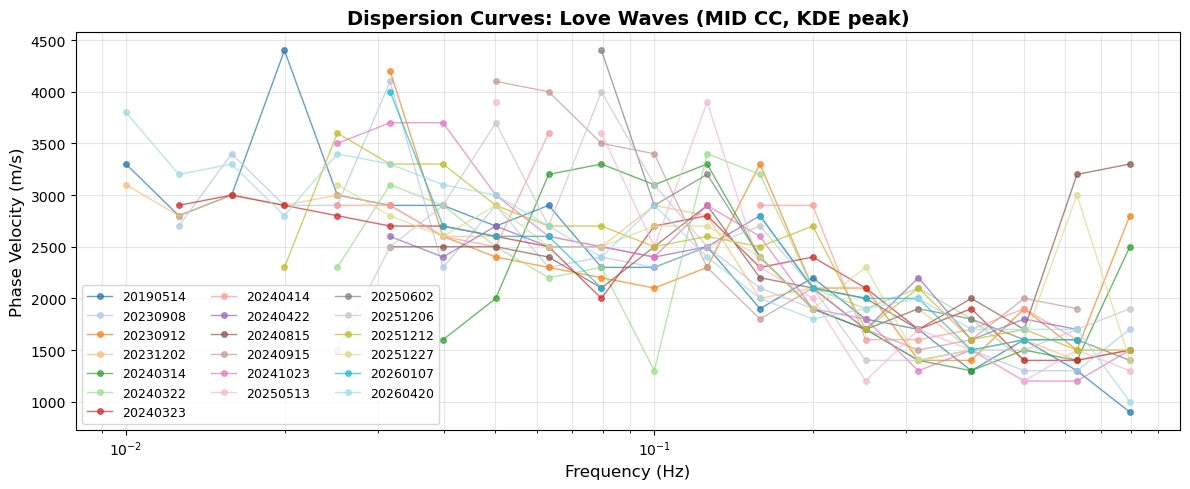

Saved: ./output/figures/dispersion_curves_kde_peak_love_mid.png



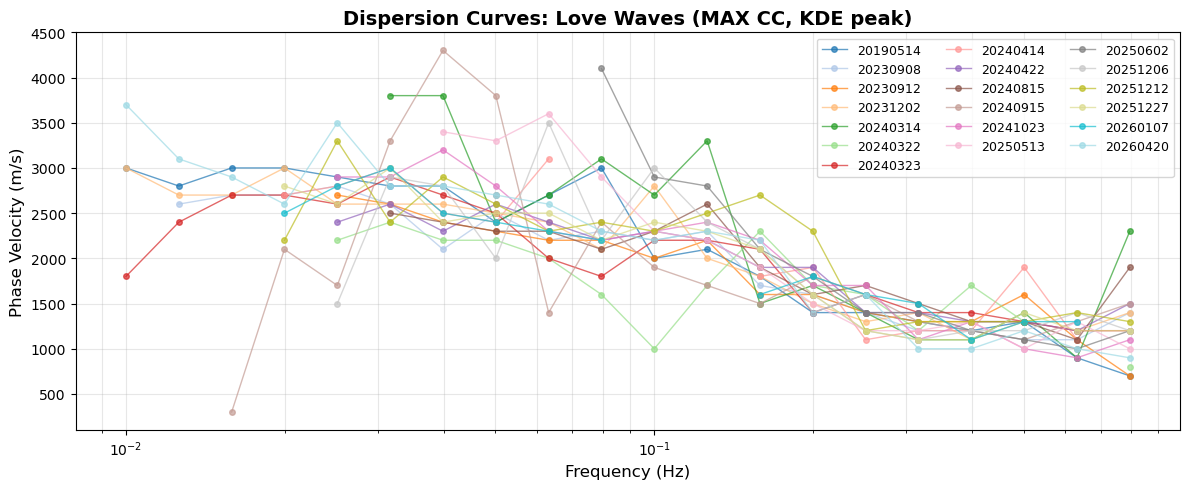

Saved: ./output/figures/dispersion_curves_kde_peak_love_max.png



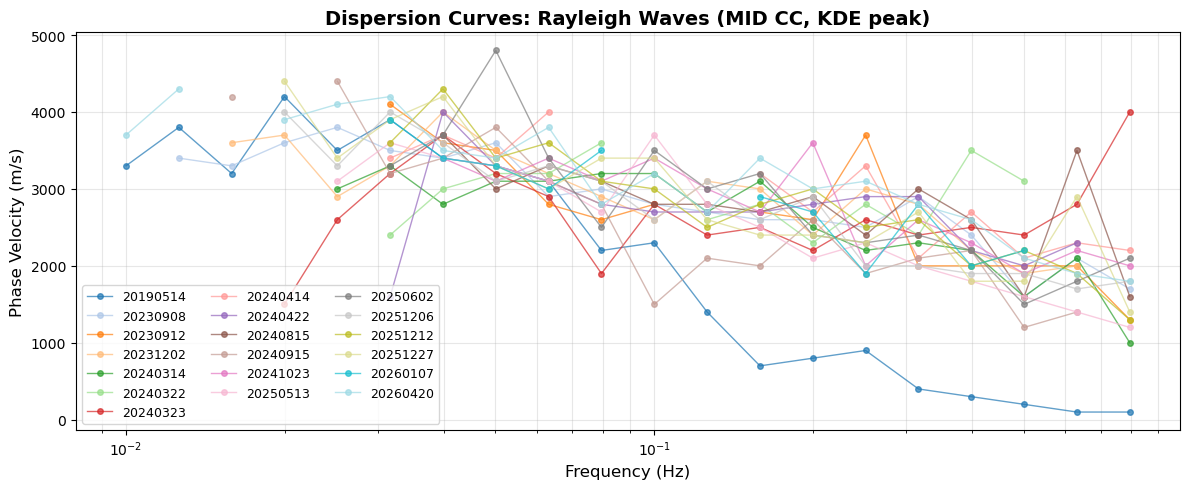

Saved: ./output/figures/dispersion_curves_kde_peak_rayleigh_mid.png



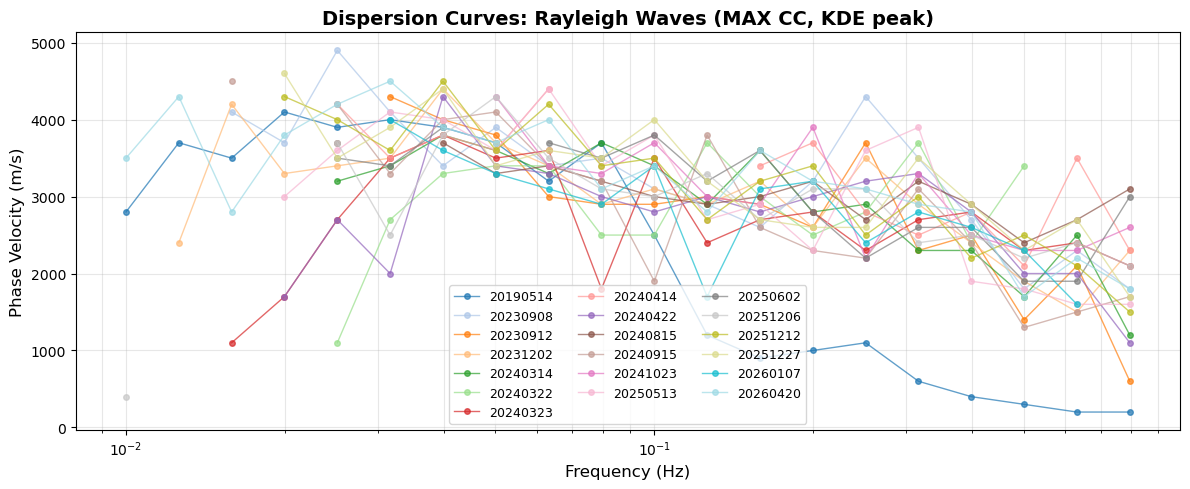

Saved: ./output/figures/dispersion_curves_kde_peak_rayleigh_max.png



In [9]:
# Plot individual curves for each combination
for key, df_merged in merged_dfs.items():
    if df_merged is None or len(df_merged.columns) == 0:
        continue
    
    wave_type, cc_method = key.split('_')
    
    fig, ax = plt.subplots(figsize=(12, 5))
    
    events = df_merged.columns.tolist()
    colors = plt.cm.tab20(np.linspace(0, 1, len(events)))
    
    for i, event_name in enumerate(events):
        ax.plot(df_merged.index, df_merged[event_name], 
               'o-', color=colors[i], label=event_name, 
               markersize=4, linewidth=1, alpha=0.7)
    
    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=12)
    ax.set_title(
        f'Dispersion Curves: {wave_type.capitalize()} Waves ({cc_method.upper()} CC, {velocity_label})',
        fontsize=14, fontweight='bold',
    )
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=9, ncol=3, loc='best')
    
    plt.tight_layout()
    plt.show()
    
    output_file = os.path.join(output_dir, f'dispersion_curves_{velocity_estimate}_{key}.png')
    fig.savefig(output_file, bbox_inches='tight', dpi=150)
    print(f"Saved: {output_file}\n")

## Plot Median and Percentiles

Plot median and percentile ranges for each wave type and CC method combination.

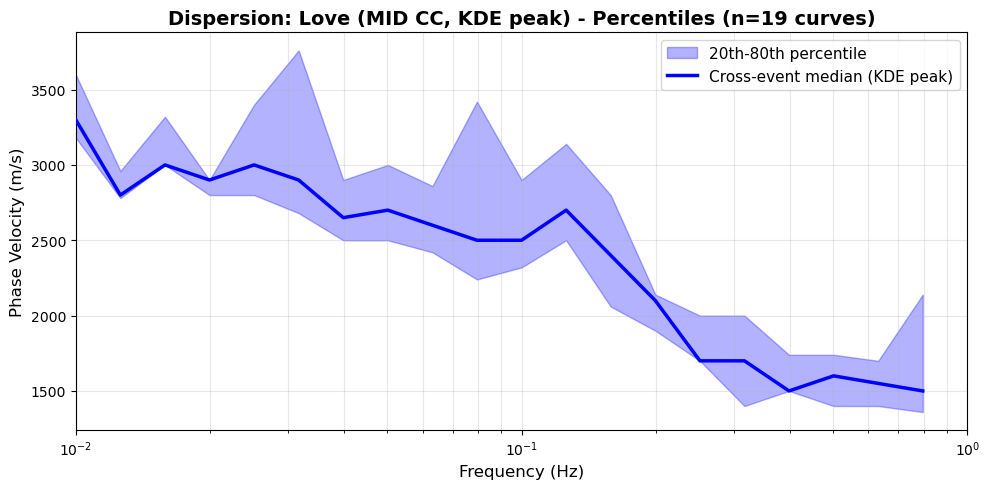

Saved: ./output/figures/dispersion_kde_peak_love_mid.png



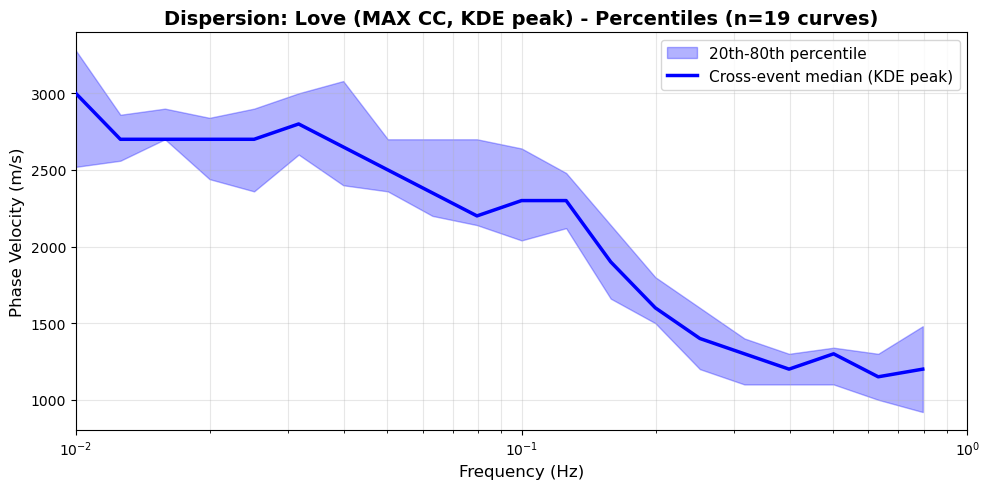

Saved: ./output/figures/dispersion_kde_peak_love_max.png



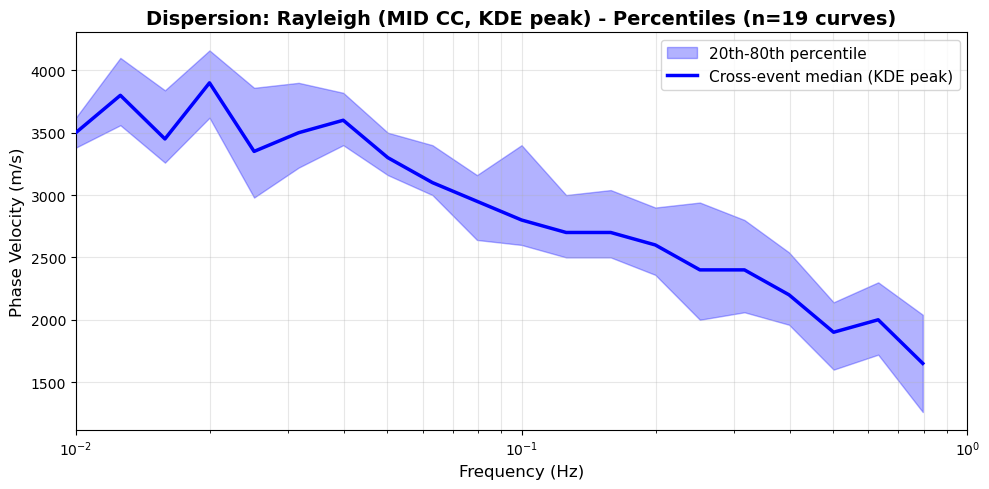

Saved: ./output/figures/dispersion_kde_peak_rayleigh_mid.png



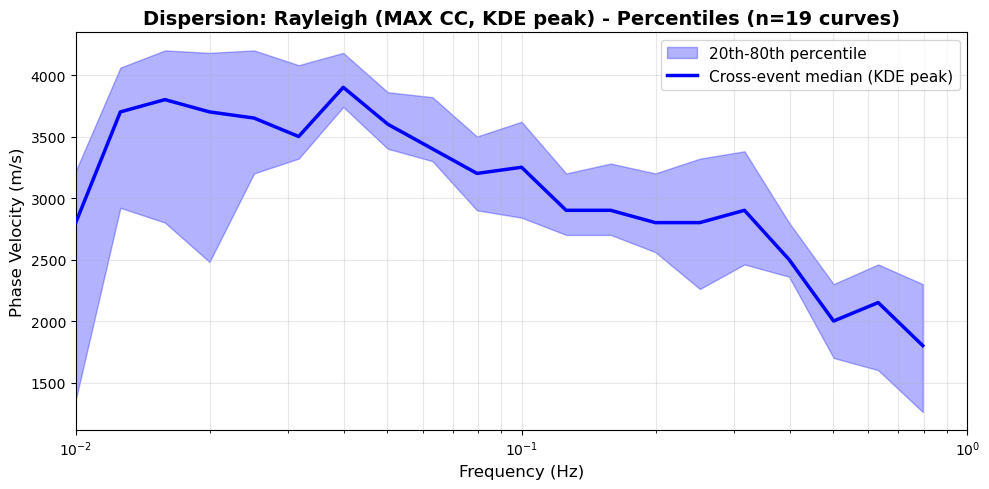

Saved: ./output/figures/dispersion_kde_peak_rayleigh_max.png



In [10]:
# Plot median and percentiles for each combination
for key, stats in statistics.items():
    if stats is None:
        continue
    
    wave_type, cc_method = key.split('_')
    
    fig, ax = plt.subplots(figsize=(10, 5))
    
    freq_array = stats['frequencies']
    median_vel = stats['median']
    p20_vel = stats['p20']
    p80_vel = stats['p80']
    
    # Plot percentile region
    ax.fill_between(freq_array, p20_vel, p80_vel, 
                    alpha=0.3, color='blue', label='20th-80th percentile')
    
    # Plot median
    curve_label = stats.get('velocity_label', velocity_label)
    ax.plot(freq_array, median_vel, 'b-', linewidth=2.5, label=f'Cross-event median ({curve_label})', zorder=5)
    
    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=12)
    ax.set_title(
        f'Dispersion: {wave_type.capitalize()} ({cc_method.upper()} CC, {curve_label}) - Percentiles (n={stats["n_events"]} curves)',
        fontsize=14, fontweight='bold',
    )
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=11, loc='best')
    
    ax.set_xlim(0.01, 1)
    plt.tight_layout()
    plt.show()
    
    output_file = os.path.join(output_dir, f'dispersion_{velocity_estimate}_{key}.png')
    fig.savefig(output_file, bbox_inches='tight', dpi=150)
    print(f"Saved: {output_file}\n")

### Load Model-based Dispersion Curves

In [11]:
dispersion_prem = pd.read_csv("./data/dispersion_prem.csv")
dispersion_local = pd.read_csv("./data/dispersion_local.csv")

ff_prem = 1/dispersion_prem["t"]
L0_prem = dispersion_prem["L0"]
R0_prem = dispersion_prem["R0"]

ff_local = 1/dispersion_local["t"]
L0_local = dispersion_local["L0"]
R0_local = dispersion_local["R0"]
R1_local = dispersion_local["R1"]
L1_local = dispersion_local["L1"]

L0_local_group = dispersion_local["L0_group"]
R0_local_group = dispersion_local["R0_group"]


## Combined Comparison Plot

Compare all wave types and CC methods together.

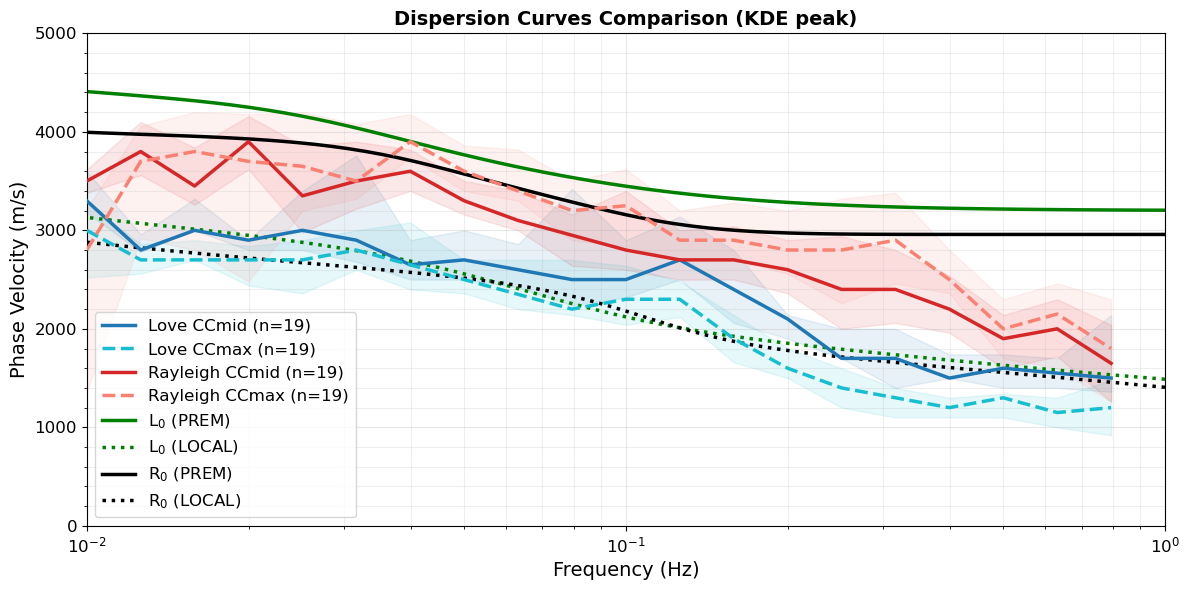

Saved: ./output/figures/dispersion_comparison_all_kde_peak.png


In [12]:
# Combined plot comparing all combinations
if len(statistics) > 0:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Colors and styles for each combination
    colors = {
        'love_mid': 'tab:blue',
        'love_max': 'tab:cyan',
        'rayleigh_mid': 'tab:red',
        'rayleigh_max': 'salmon',
    }
    
    linestyles = {
        'love_mid': '-',
        'love_max': '--',
        'rayleigh_mid': '-',
        'rayleigh_max': '--',
    }
    
    labels = {
        'love_mid': 'Love CCmid',
        'love_max': 'Love CCmax',
        'rayleigh_mid': 'Rayleigh CCmid',
        'rayleigh_max': 'Rayleigh CCmax',
    }
    
    # First, plot the shaded percentile areas (behind the lines)
    for key, stats in statistics.items():
        if stats is None:
            continue
        
        freq_array = stats['frequencies']
        p20_vel = stats['p20']
        p80_vel = stats['p80']
        
        # Plot shaded area for 20-80th percentile
        ax.fill_between(
            freq_array, p20_vel, p80_vel,
            color=colors.get(key, 'gray'),
            alpha=0.1,
            zorder=1
        )
    
    # Then, plot the median lines (on top)
    for key, stats in statistics.items():
        if stats is None:
            continue
        
        freq_array = stats['frequencies']
        median_vel = stats['median']
        
        ax.plot(
            freq_array, median_vel, 
            color=colors.get(key, 'gray'),
            linestyle=linestyles.get(key, '-'),
            linewidth=2.5, 
            label=f"{labels.get(key, key)} (n={stats['n_events']})",
            zorder=5
        )
    
    # plot model-based dispersion curves
    ax.plot(ff_prem, L0_prem*1000, 'g-', label='L$_0$ (PREM)', linewidth=2.5)
    ax.plot(ff_local, L0_local*1000, 'g:', label='L$_0$ (LOCAL)', linewidth=2.5)

    ax.plot(ff_prem, R0_prem*1000, 'k-', label='R$_0$ (PREM)', linewidth=2.5)
    ax.plot(ff_local, R0_local*1000, 'k:', label='R$_0$ (LOCAL)', linewidth=2.5)

    ax.set_xlabel('Frequency (Hz)', fontsize=14)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=14)
    ax.set_title(f'Dispersion Curves Comparison ({velocity_label})',
                 fontsize=14, fontweight='bold')
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=12, loc='best')
    ax.set_xlim(0.01, 1)
    ax.set_ylim(0, 5000)
    ax.tick_params(axis='both', which='major', labelsize=12)
    
    # add minor gridlines with mpl
    ax.minorticks_on()
    ax.grid(True, which='minor', alpha=0.2)

    plt.tight_layout()
    plt.show()
    
    output_file = os.path.join(output_dir, f'dispersion_comparison_all_{velocity_estimate}.png')
    fig.savefig(output_file, bbox_inches='tight', dpi=200)
    print(f"Saved: {output_file}")
else:
    print("Cannot create combined plot - no statistics available")

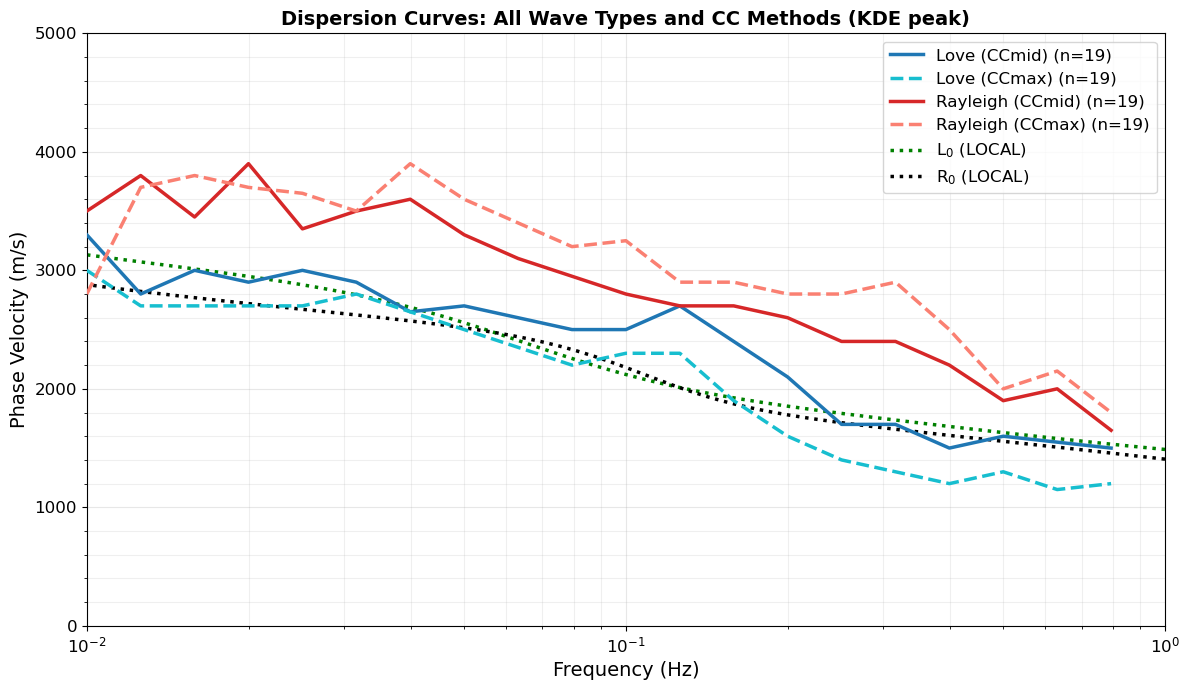

Saved: ./output/figures/dispersion_comparison_all_kde_peak.png


In [13]:
# Combined plot comparing all combinations
if len(statistics) > 0:
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Colors and styles for each combination
    colors = {
        'love_mid': 'tab:blue',
        'love_max': 'tab:cyan',
        'rayleigh_mid': 'tab:red',
        'rayleigh_max': 'salmon',
    }
    
    linestyles = {
        'love_mid': '-',
        'love_max': '--',
        'rayleigh_mid': '-',
        'rayleigh_max': '--',
    }
    
    labels = {
        'love_mid': 'Love (CCmid)',
        'love_max': 'Love (CCmax)',
        'rayleigh_mid': 'Rayleigh (CCmid)',
        'rayleigh_max': 'Rayleigh (CCmax)',
    }
    
    for key, stats in statistics.items():
        if stats is None:
            continue
        
        freq_array = stats['frequencies']
        median_vel = stats['median']
        
        ax.plot(
            freq_array, median_vel, 
            color=colors.get(key, 'gray'),
            linestyle=linestyles.get(key, '-'),
            linewidth=2.5, 
            label=f"{labels.get(key, key)} (n={stats['n_events']})",
            zorder=5
        )

        # ax.errorbar(freq_array, median_vel, yerr=p80_vel - p20_vel, fmt='o', color=colors.get(key, 'gray'), 
        #             linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)

    # plot model-based dispersion curves
    # ax.plot(ff_prem, L0_prem*1000, 'g-', label='L$_0$ (PREM)', linewidth=2.5)
    ax.plot(ff_local, L0_local*1000, 'g:', label='L$_0$ (LOCAL)', linewidth=2.5)

    # ax.plot(ff_prem, R0_prem*1000, 'k-', label='R$_0$ (PREM)', linewidth=2.5)
    ax.plot(ff_local, R0_local*1000, 'k:', label='R$_0$ (LOCAL)', linewidth=2.5)

    ax.set_xlabel('Frequency (Hz)', fontsize=14)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=14)
    ax.set_title(
        f'Dispersion Curves: All Wave Types and CC Methods ({velocity_label})',
        fontsize=14, fontweight='bold',
    )
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=12, loc='best')
    ax.set_xlim(0.01, 1)
    ax.set_ylim(0, 5000)
    ax.tick_params(axis='both', which='major', labelsize=12)
    
    # add minor gridlines with mpl
    ax.minorticks_on()
    ax.grid(True, which='minor', alpha=0.2)
        
    plt.tight_layout()
    plt.show()
    
    # output_file = os.path.join(output_dir, 'dispersion_comparison_all.png')
    # fig.savefig(output_file, bbox_inches='tight', dpi=150)
    print(f"Saved: {output_file}")
else:
    print("Cannot create combined plot - no statistics available")

## Publication Figure

In [14]:
output_dir = "./output/figures/publication"
os.makedirs(output_dir, exist_ok=True)

# Publication-style defaults
plt.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "ytick.minor.visible": True,
    "xtick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 200,
})

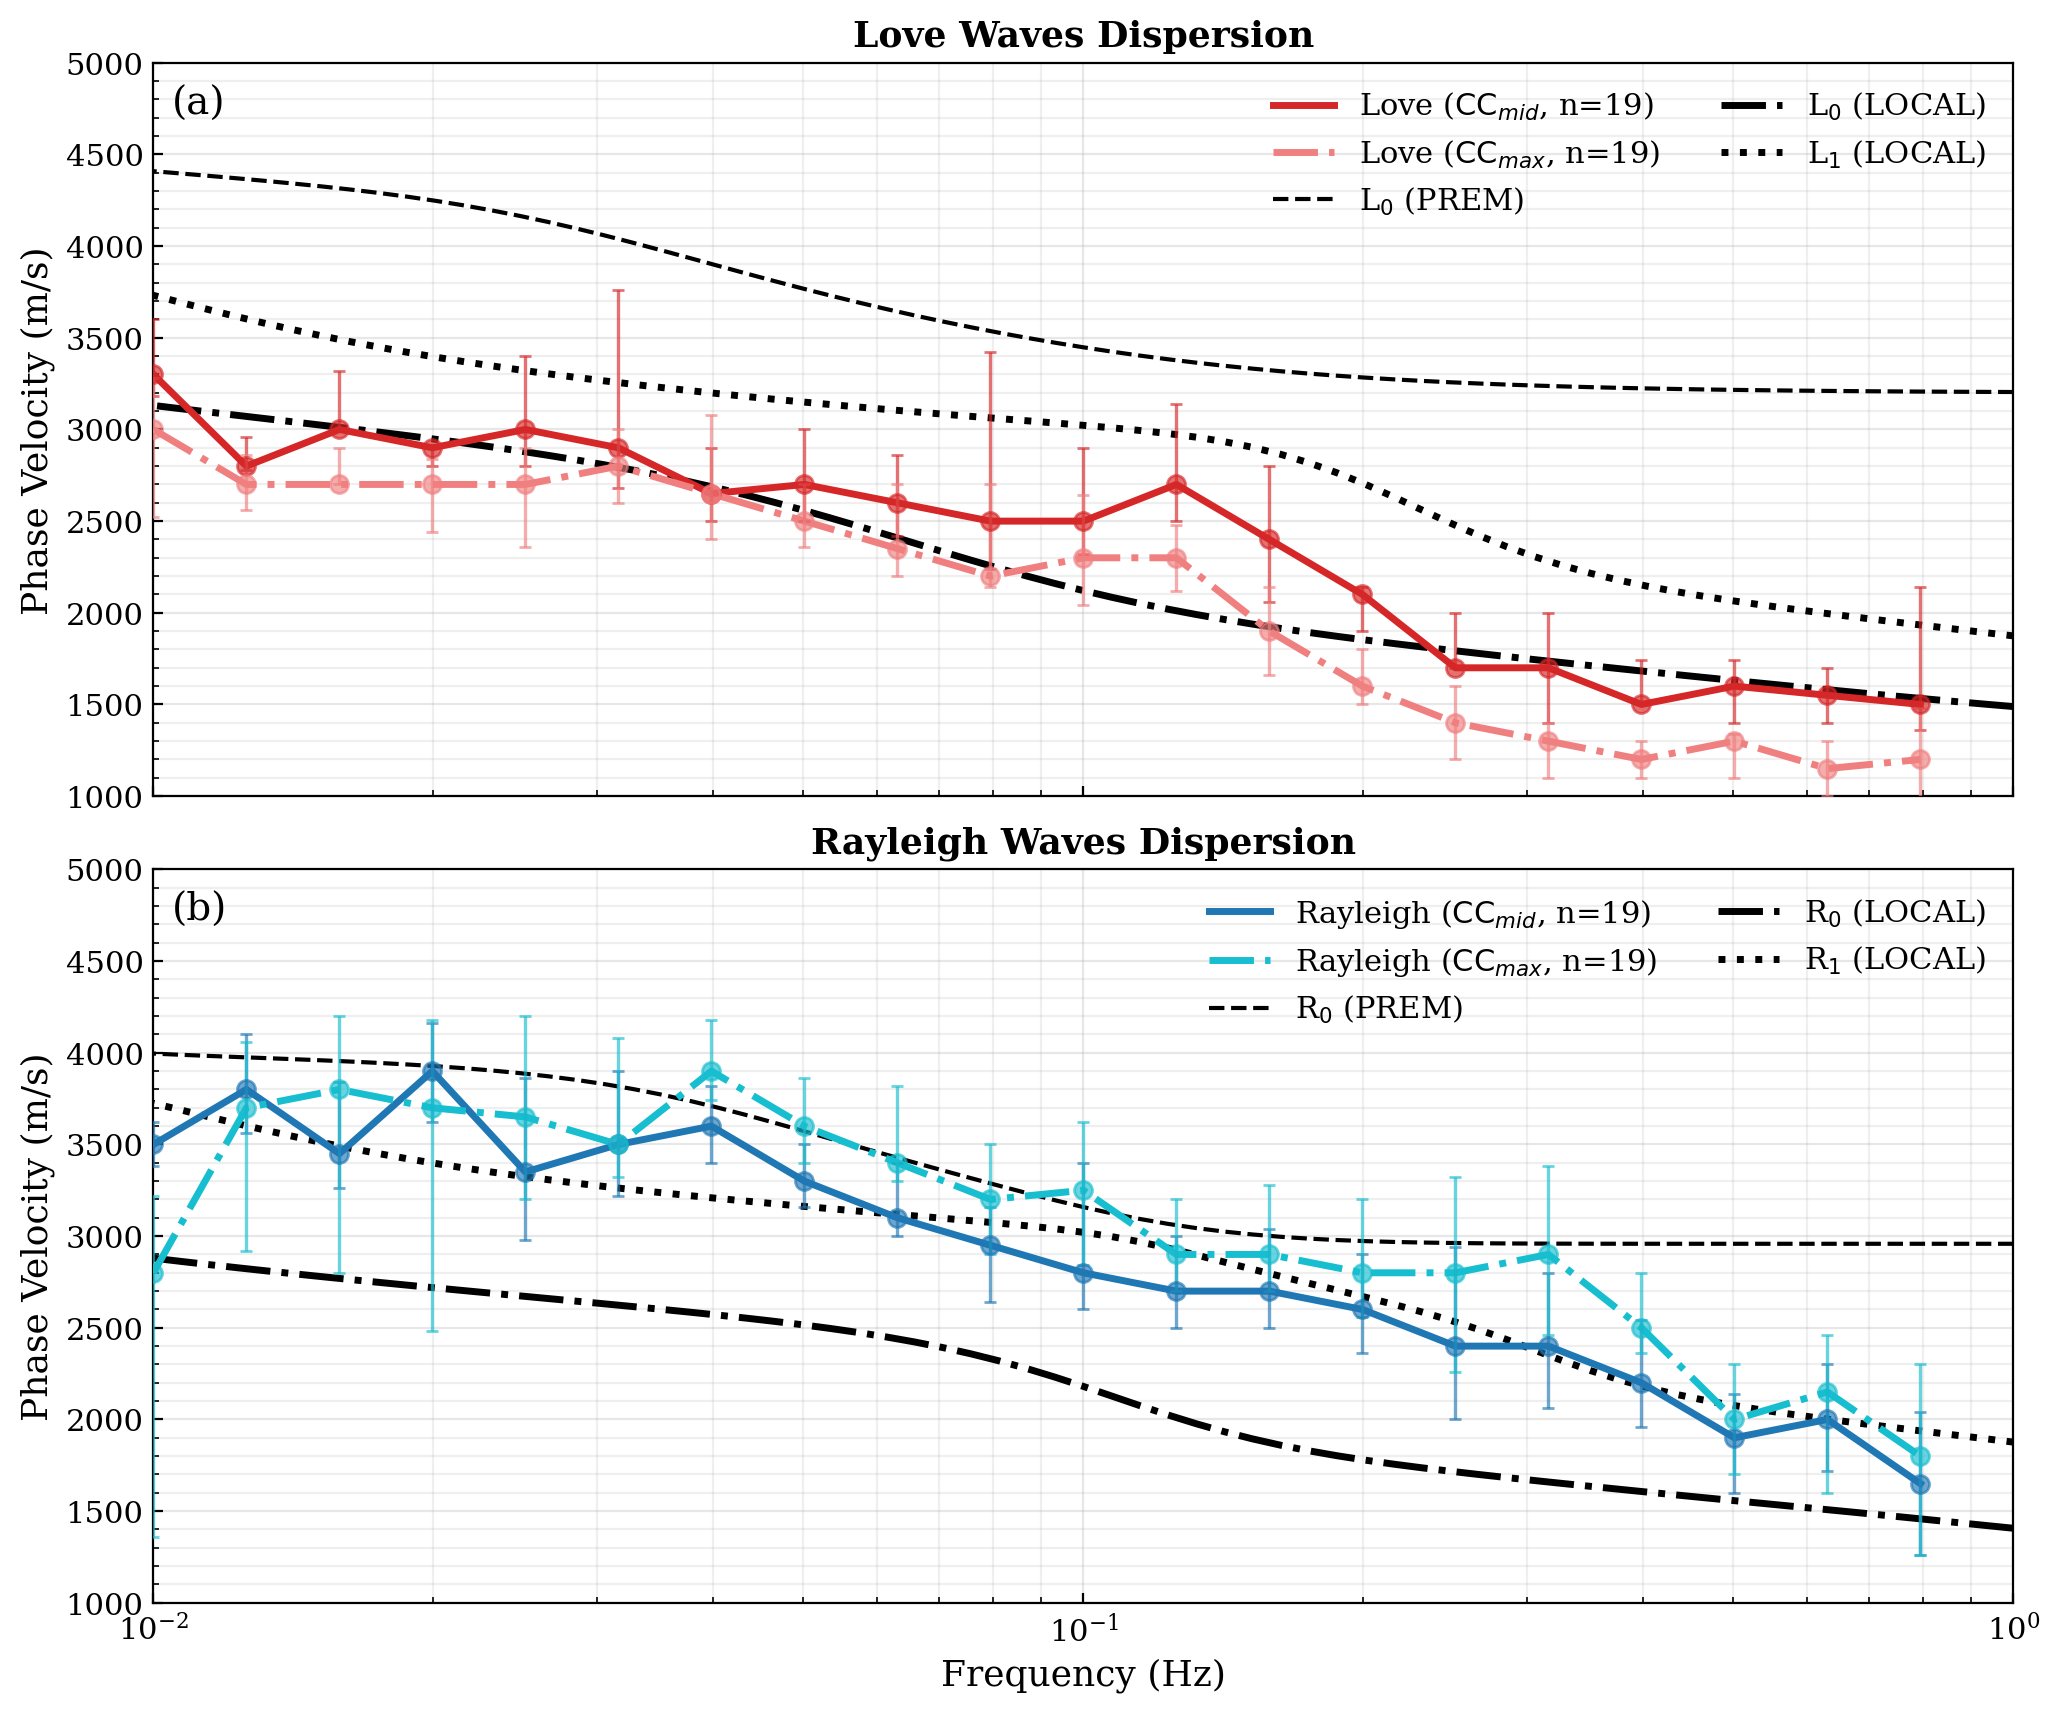

Saved: ./output/figures/romy_dispersions_curves_kde_peak_mid_max.png


In [19]:
# Two vertical subplots: Love (top) and Rayleigh (bottom)
# with optional scatter points and error bars around median curves

# -----------------------------
# Plot options
# -----------------------------
show_scatter = True
show_errorbars = True          # only used when show_scatter=True
scatter_stride = 1             # set to 2 or 3 to thin points
scatter_size = 42              # marker size
scatter_alpha = 1
error_alpha = 0.65
error_linewidth = 1.2
capsize = 2

# -----------------------------
# Build figure
# -----------------------------
if len(statistics) > 0:
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
    ax_love, ax_ray = axes

    plt.subplots_adjust(hspace=0.1)

    # Styles for CC methods
    cc_colors = {
        "mid": "tab:blue",
        "max": "tab:cyan",
    }
    cc_linestyles = {
        "mid": "-",
        "max": "-.",
    }

    # Helper to draw one curve + optional scatter/errorbars
    def _plot_stat_curve(ax, freq_array, median_vel, p20_vel, p80_vel, wave_type, cc_method, label):
        if wave_type == "love":
            color_map = {"mid": "tab:red", "max": "lightcoral"}
        else:  # rayleigh
            color_map = {"mid": "tab:blue", "max": "tab:cyan"}

        # if wave_type == "rayleigh":
        #     correction_factor = 0.75
        #     median_vel = median_vel * correction_factor
        #     p20_vel = p20_vel * correction_factor
        #     p80_vel = p80_vel * correction_factor

        color = color_map.get(cc_method, "gray")
        linestyle = cc_linestyles.get(cc_method, "-")

        if cc_method == "mid":
            ccmeth = r"$\text{CC}_{mid}$"
        elif cc_method == "max":
            ccmeth = r"$\text{CC}_{max}$"
        else:
            ccmeth = cc_method.upper()

        curve_label = stats.get('velocity_label', velocity_label)
        label = f"{wave_type.capitalize()} ({ccmeth}, n={stats['n_events']})"

        # Main summary line (cross-event median of selected per-event estimate)
        ax.plot(
            freq_array,
            median_vel,
            color=color,
            linestyle=linestyle,
            linewidth=2.5,
            label=label,
            zorder=3,
        )

        # Optional scatter/errorbars
        if show_scatter:
            idx = np.arange(0, len(freq_array), scatter_stride)

            if show_errorbars:
                # asymmetric error from percentile envelope
                lower = (median_vel - p20_vel).values if hasattr(median_vel, "values") else (median_vel - p20_vel)
                upper = (p80_vel - median_vel).values if hasattr(median_vel, "values") else (p80_vel - median_vel)
                yerr = np.vstack([lower, upper])

                ax.errorbar(
                    np.asarray(freq_array)[idx],
                    np.asarray(median_vel)[idx],
                    yerr=yerr[:, idx],
                    fmt="o",
                    ms=np.sqrt(scatter_size),
                    color=color,
                    ecolor=color,
                    elinewidth=error_linewidth,
                    capsize=capsize,
                    alpha=error_alpha,
                    zorder=9,
                )
            else:
                ax.scatter(
                    np.asarray(freq_array)[idx],
                    np.asarray(median_vel)[idx],
                    s=scatter_size,
                    color=color,
                    alpha=scatter_alpha,
                    zorder=9,
                )

    # Plot stats by wave type / cc method
    for key, stats in statistics.items():
        if stats is None:
            continue

        wave_type, cc_method = key.split("_")
        freq_array = stats["frequencies"]
        median_vel = stats["median"]
        p20_vel = stats["p20"]
        p80_vel = stats["p80"]

        label = f"{wave_type.capitalize()} (n={stats['n_events']})"

        if wave_type == "love":
            ax = ax_love
        elif wave_type == "rayleigh":
            ax = ax_ray
        else:
            continue

        _plot_stat_curve(
            ax=ax,
            freq_array=freq_array,
            median_vel=median_vel,
            p20_vel=p20_vel,
            p80_vel=p80_vel,
            wave_type=wave_type,
            cc_method=cc_method,
            label=label,
        )

    # Add model curves (PREM)
    ax_love.plot(ff_prem, L0_prem * 1000, color="k", linestyle="--", linewidth=1.5, label="L$_0$ (PREM)")
    ax_ray.plot(ff_prem, R0_prem * 1000, color="k", linestyle="--", linewidth=1.5, label="R$_0$ (PREM)")

    # Add model curves (LOCAL)
    ax_love.plot(ff_local, L0_local * 1000, color="k", linestyle="-.", linewidth=2.5, label="L$_0$ (LOCAL)")
    ax_ray.plot(ff_local, R0_local * 1000, color="k", linestyle="-.", linewidth=2.5, label="R$_0$ (LOCAL)")
    
    ax_love.plot(ff_local, L1_local * 1000, color="k", linestyle=":", linewidth=2.5, label="L$_1$ (LOCAL)")
    ax_ray.plot(ff_local, R1_local * 1000, color="k", linestyle=":", linewidth=2.5, label="R$_1$ (LOCAL)")

    # Add model group curves (LOCAL)
    # ax_love.plot(ff_local, L0_local_group * 1000, color="k", linestyle="-", linewidth=2.5, label="L$_0$ (LOCAL)")
    # ax_ray.plot(ff_local, R0_local_group * 1000, color="k", linestyle="-", linewidth=2.5, label="R$_0$ (LOCAL)")

    # Common formatting helper
    def _format_axis(ax, title):
        ax.set_ylabel("Phase Velocity (m/s)", fontsize=13)
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.set_xscale("log")
        ax.set_xlim(0.01, 1)
        ax.set_ylim(1000, 5000)
        ax.grid(True, alpha=0.3, which="both")
        ax.minorticks_on()
        ax.grid(True, which="minor", alpha=0.2)
        ax.tick_params(axis="both", which="major", labelsize=11)
        ax.legend(fontsize=11, loc="best", ncol=2)

    _format_axis(ax_love, f"Love Waves Dispersion")
    _format_axis(ax_ray, f"Rayleigh Waves Dispersion")
    ax_ray.set_xlabel("Frequency (Hz)", fontsize=13)

    # Add label (a) and (b) to the top of the plot
    ax_love.text(0.01, 0.97, "(a)", transform=ax_love.transAxes, fontsize=14, va="top", ha="left")
    ax_ray.text(0.01, 0.97, "(b)", transform=ax_ray.transAxes, fontsize=14, va="top", ha="left")

    plt.show()


output_file = os.path.join(output_dir, f"romy_dispersions_curves_{velocity_estimate}_mid_max.png")
fig.savefig(output_file, dpi=150, bbox_inches="tight")
print(f"Saved: {output_file}")